<a href="https://colab.research.google.com/github/torpidcop/Chatgpt-review-analysis/blob/main/chatgpt_reviews_sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ChatGPT Reviews: Sentiment & Text Analysis

**Goal:** analyze user reviews of the ChatGPT app to understand sentiment, how it relates to star ratings, and what users praise most.

**Steps:** 1) Data preparation 2) Sentiment analysis 3) Text analysis of positive reviews 4) Visualization and conclusions

In [3]:
!pip install -q textblob wordcloud

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob
from wordcloud import WordCloud
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
from tqdm.auto import tqdm

tqdm.pandas()
sns.set_theme(style="whitegrid", context="notebook")

## 1. Data Preparation
### 1.1 Load and inspect the dataset

In [4]:
# Option A: upload the CSV from your computer
from google.colab import files
uploaded = files.upload()          # select chatgpt_reviews.csv
CSV_PATH = "chatgpt_reviews.csv"

# Option B: load from Google Drive instead (uncomment)
# from google.colab import drive
# drive.mount('/content/drive')
# CSV_PATH = "/content/drive/MyDrive/chatgpt_reviews.csv"

df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
df.head()

Saving chatgpt_reviews.csv to chatgpt_reviews.csv
Shape: (196727, 4)


,Review Id,Review,Ratings,Review Date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39


In [5]:
df.info()
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate review ids:", df["Review Id"].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196727 entries, 0 to 196726
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Review Id    196727 non-null  object
 1   Review       196721 non-null  object
 2   Ratings      196727 non-null  int64 
 3   Review Date  196727 non-null  object
dtypes: int64(1), object(3)
memory usage: 6.0+ MB

Missing values:
Review Id      0
Review         6
Ratings        0
Review Date    0
dtype: int64

Duplicate review ids: 3573


### 1.2 Standardize column names

In [6]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
df = df.rename(columns={"ratings": "rating"})
print(df.columns.tolist())

['review_id', 'review', 'rating', 'review_date']


### 1.3 Handle missing values, fix data types, remove duplicates

In [7]:
# Data types
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df["review_date"] = pd.to_datetime(df["review_date"], errors="coerce")

# Missing values: fill empty reviews, drop rows without a rating or date
df["review"] = df["review"].fillna("").astype(str).str.strip()
df = df.dropna(subset=["rating", "review_date"])
df["rating"] = df["rating"].astype(int)

# Duplicates
before = len(df)
df = df.drop_duplicates(subset="review_id", keep="first").reset_index(drop=True)
print(f"Removed {before - len(df):,} duplicate reviews")

df.dtypes

Removed 3,573 duplicate reviews


,0
review_id,object
review,object
rating,int64
review_date,datetime64[ns]


### 1.4 Clean the review text

In [8]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # remove URLs
    text = re.sub(r"[^a-z\s']", " ", text)          # keep letters and apostrophes
    return re.sub(r"\s+", " ", text).strip()

df["clean_review"] = df["review"].apply(clean_text)
df["review_length"] = df["clean_review"].str.split().str.len()
df["month"] = df["review_date"].dt.to_period("M").dt.to_timestamp()

# Reviews with no text cannot be scored
df_text = df[df["clean_review"] != ""].copy()
print("Reviews with text:", len(df_text))
df_text.head()

Reviews with text: 186661


,review_id,review,rating,review_date,clean_review,review_length,month
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05,good,1,2024-08-01
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18,good,1,2024-08-01
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59,nice app,2,2024-08-01
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50,nice ig,2,2024-08-01
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39,this is a great app the bot is so accurate to ...,68,2024-08-01


## 2. Sentiment Analysis
### 2.1 Polarity and subjectivity (TextBlob)
- **Polarity:** -1 (very negative) to +1 (very positive)
- **Subjectivity:** 0 (objective) to 1 (subjective / opinion)

This step scores ~190k reviews, so it can take a few minutes.

In [9]:
def get_sentiment(text):
    s = TextBlob(text).sentiment
    return s.polarity, s.subjectivity

scores = df_text["clean_review"].progress_apply(get_sentiment)
df_text["polarity"] = scores.str[0]
df_text["subjectivity"] = scores.str[1]
df_text[["review", "rating", "polarity", "subjectivity"]].head()

  0%|          | 0/186661 [00:00<?, ?it/s]

,review,rating,polarity,subjectivity
0,good,5,0.7,0.600000
1,good,5,0.7,0.600000
2,nice app,5,0.6,1.000000
3,"nice, ig",5,0.6,1.000000
4,"this is a great app, the bot is so accurate to...",5,0.4,0.542949


### 2.2 Categorize reviews as Positive, Neutral or Negative

In [10]:
POS_T, NEG_T = 0.05, -0.05

def categorize(p):
    if p > POS_T:  return "Positive"
    if p < NEG_T:  return "Negative"
    return "Neutral"

df_text["sentiment"] = df_text["polarity"].apply(categorize)

order = ["Negative", "Neutral", "Positive"]
colors = {"Negative": "#d9534f", "Neutral": "#f0ad4e", "Positive": "#5cb85c"}

print((df_text["sentiment"].value_counts(normalize=True) * 100).round(2))

sentiment
Positive    79.03
Neutral     17.20
Negative     3.77
Name: proportion, dtype: float64


## 3. Visualizing Sentiment
### 3.1 Sentiment distribution

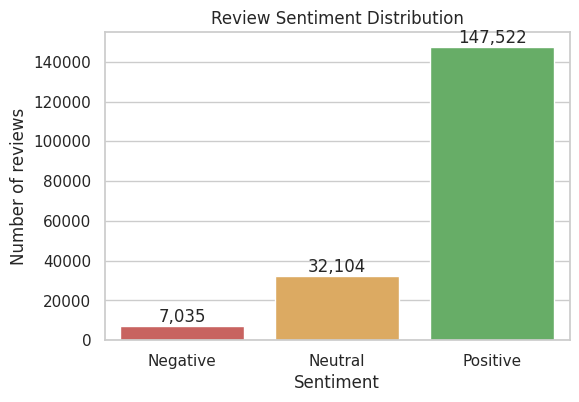

In [11]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_text, x="sentiment", order=order,
                   hue="sentiment", palette=colors, legend=False)
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.0f}")
ax.set(title="Review Sentiment Distribution", xlabel="Sentiment", ylabel="Number of reviews")
plt.show()

### 3.2 Polarity and subjectivity distributions

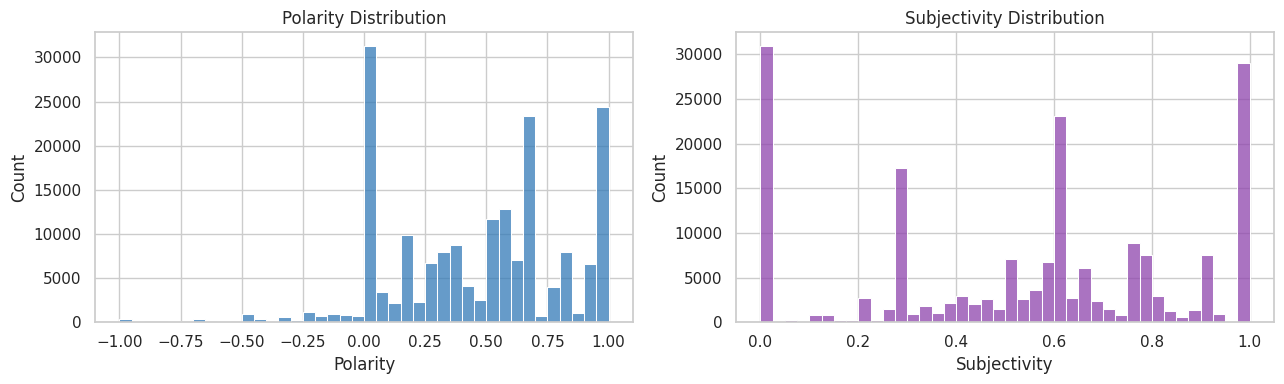

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_text["polarity"], bins=40, color="#337ab7", ax=axes[0])
axes[0].set(title="Polarity Distribution", xlabel="Polarity")
sns.histplot(df_text["subjectivity"], bins=40, color="#8e44ad", ax=axes[1])
axes[1].set(title="Subjectivity Distribution", xlabel="Subjectivity")
plt.tight_layout()
plt.show()

### 3.3 Sentiment vs. user ratings

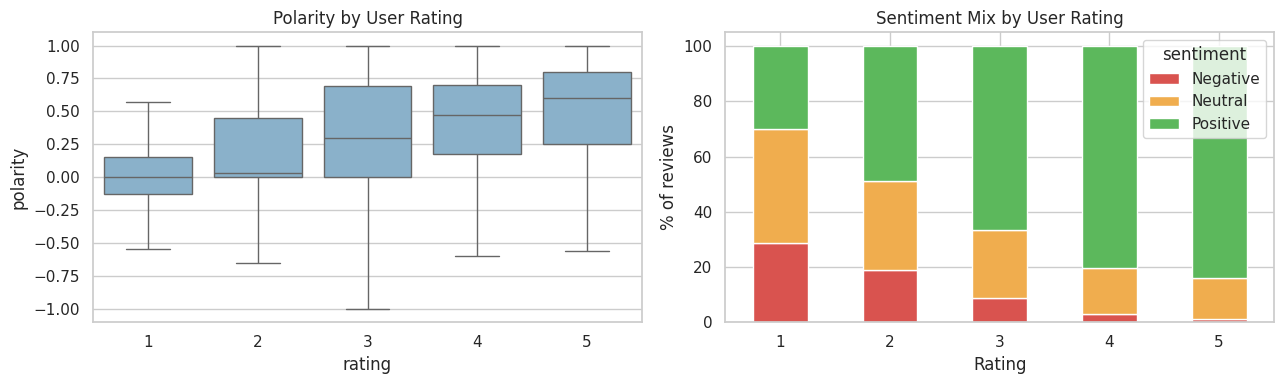

sentiment  Negative  Neutral  Positive
rating                                
1              28.5     41.3      30.1
2              19.0     32.1      48.9
3               8.7     24.7      66.6
4               3.2     16.6      80.2
5               1.3     14.6      84.1

Average polarity by rating:
rating
1    0.014
2    0.166
3    0.320
4    0.440
5    0.520
Name: polarity, dtype: float64


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(data=df_text, x="rating", y="polarity", color="#7fb3d5",
            showfliers=False, ax=axes[0])
axes[0].set_title("Polarity by User Rating")

ct = pd.crosstab(df_text["rating"], df_text["sentiment"], normalize="index")[order] * 100
ct.plot(kind="bar", stacked=True, color=[colors[c] for c in order], ax=axes[1])
axes[1].set(title="Sentiment Mix by User Rating", xlabel="Rating", ylabel="% of reviews")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print(ct.round(1))
print("\nAverage polarity by rating:")
print(df_text.groupby("rating")["polarity"].mean().round(3))

### 3.4 Sentiment trend over time

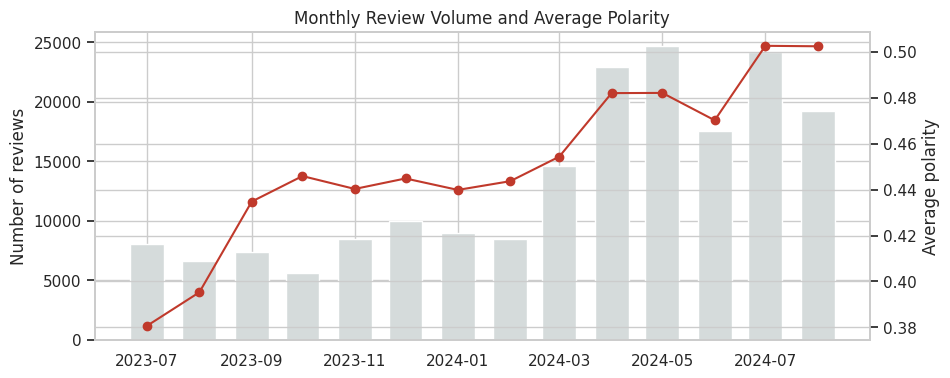

In [14]:
monthly = (df_text.groupby("month")
           .agg(avg_polarity=("polarity", "mean"), reviews=("polarity", "size"))
           .reset_index())

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(monthly["month"], monthly["reviews"], width=20, color="#d5dbdb")
ax1.set_ylabel("Number of reviews")
ax2 = ax1.twinx()
ax2.plot(monthly["month"], monthly["avg_polarity"], color="#c0392b", marker="o")
ax2.set_ylabel("Average polarity")
plt.title("Monthly Review Volume and Average Polarity")
plt.show()

## 4. Text Analysis of Positively Rated Reviews
We treat **4 and 5 star** reviews as positively rated, then look for the most frequent words and phrases.

In [15]:
pos = df_text[df_text["rating"] >= 4]
print("Positively rated reviews:", len(pos))

GENERIC = {"app", "chatgpt", "chat", "gpt", "good", "great", "nice", "best"}
STOP = list(ENGLISH_STOP_WORDS | {"im", "ive", "dont", "doesnt"})

def top_terms(texts, ngram_range, n=20, extra_stop=()):
    vec = CountVectorizer(stop_words=STOP + list(extra_stop), ngram_range=ngram_range,
                          min_df=5, token_pattern=r"(?u)\b[a-z][a-z']+\b")
    counts = vec.fit_transform(texts)
    freq = np.asarray(counts.sum(axis=0)).ravel()
    return pd.Series(freq, index=vec.get_feature_names_out()).sort_values(ascending=False).head(n)

top_words = top_terms(pos["clean_review"], (1, 1))
top_words_content = top_terms(pos["clean_review"], (1, 1), extra_stop=GENERIC)
top_bigrams = top_terms(pos["clean_review"], (2, 2))

top_words.head(10)

Positively rated reviews: 164348


,0
app,44033
good,35284
best,17627
it's,15274
nice,12798
great,11164
helpful,11022
ai,10408
chatgpt,8714
amazing,8412


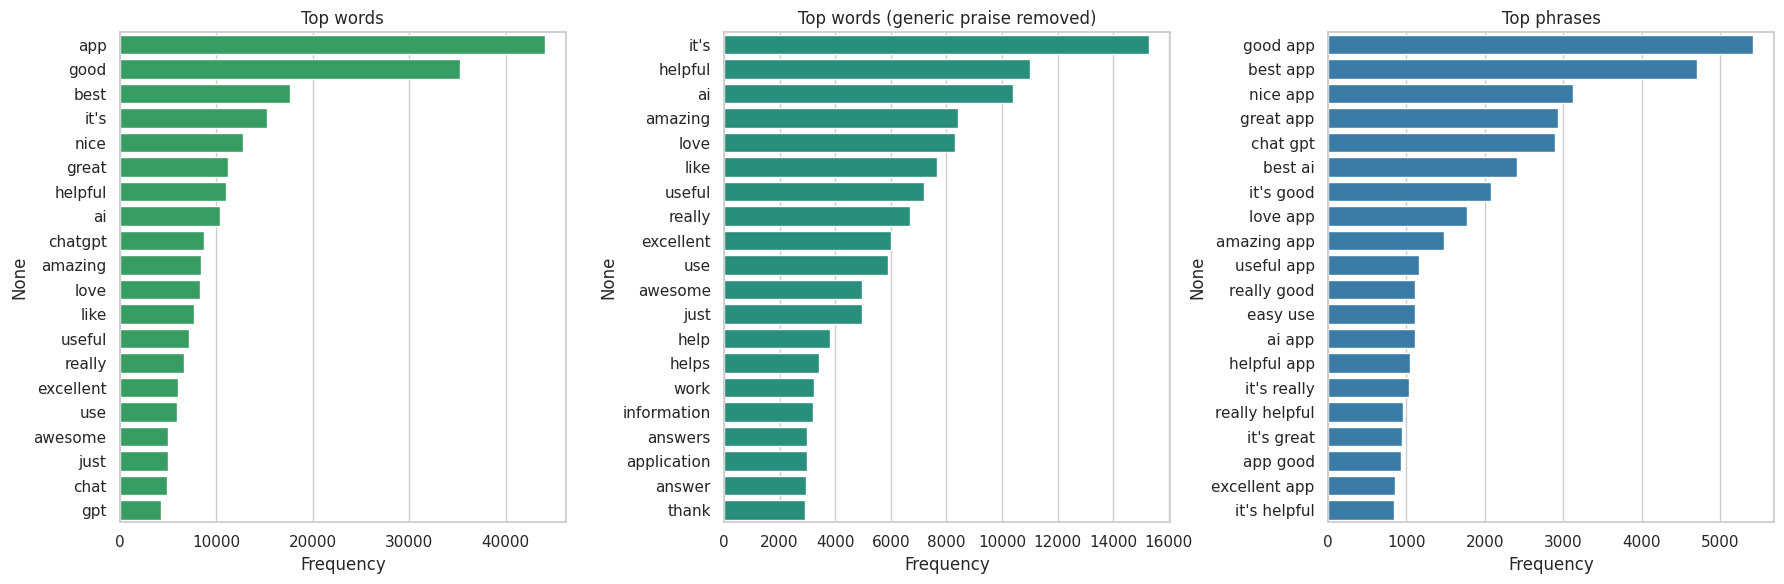

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, series, title, color in zip(
        axes,
        [top_words, top_words_content, top_bigrams],
        ["Top words", "Top words (generic praise removed)", "Top phrases"],
        ["#27ae60", "#16a085", "#2980b9"]):
    sns.barplot(x=series.values, y=series.index, color=color, ax=ax)
    ax.set(title=title, xlabel="Frequency")
plt.tight_layout()
plt.show()

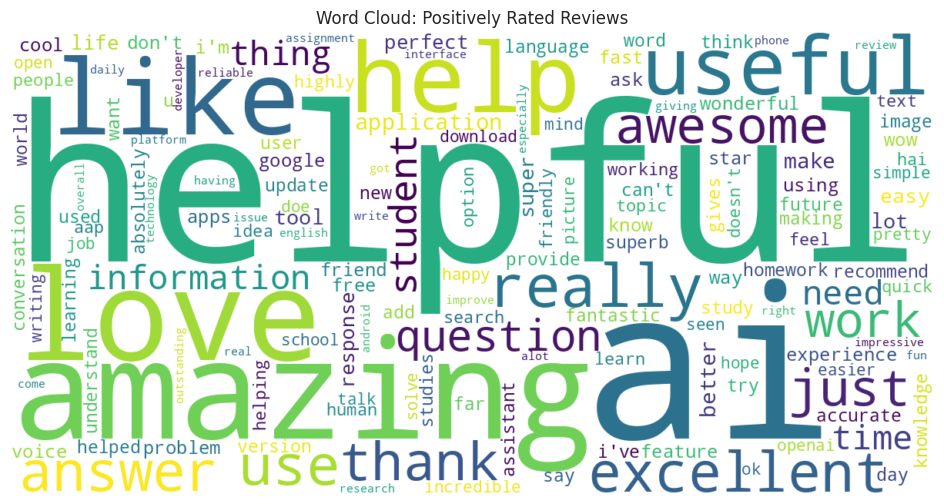

In [17]:
wc = WordCloud(width=1200, height=600, background_color="white", colormap="viridis",
               stopwords=set(STOP) | GENERIC, max_words=150, collocations=False)
wc.generate(" ".join(pos["clean_review"]))

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud: Positively Rated Reviews")
plt.show()

## 5. Extra Checks: Where Stars and Text Disagree

In [18]:
high_neg = df_text[(df_text["rating"] >= 4) & (df_text["sentiment"] == "Negative")]
low_pos = df_text[(df_text["rating"] <= 2) & (df_text["sentiment"] == "Positive")]
print("4-5 star reviews with negative text sentiment:", len(high_neg))
print("1-2 star reviews with positive text sentiment:", len(low_pos))

high_neg[["review", "rating", "polarity"]].head(5)

4-5 star reviews with negative text sentiment: 2500
1-2 star reviews with positive text sentiment: 4996


,review,rating,polarity
229,"there are typing bug. if I backspace, previous...",4,-0.166667
467,I never tried it yet but at least now,5,-0.300000
812,Extreme level response from GPT.,5,-0.125000
833,fascinating in some aspects a little frustrati...,4,-0.107500
885,Most reliable and versatile AI at the moment. ...,5,-0.200000
